# TimeToRead Agent, built from scratch

An AI agent that answers: **"How long would it take to read this text at 200 words per minute?"**

> **Note:** this task doesn't need an agent; a simple function could do it. It was chosen because it's small enough to see every step of the agent loop clearly.

It uses only the Anthropic Python SDK, with no agent framework, so every part of the agent is visible:

| Part | What it does |
|---|---|
| **Tools** | Plain Python functions the agent can ask to run (word counter, calculator) |
| **Tool schema** | Descriptions the model reads to decide *which* tool to call |
| **Agent loop** | Perceive → Plan → Act → Adapt, repeated until the model gives a final answer |
| **Metrics** | Tokens, cost, reasoning summary and tool calls for each step, returned as data and graphed after the run |

In [1]:
import itertools  # running totals for the cost graph
import re         # regular expressions for cleaning text and math expressions

import anthropic                 # Anthropic SDK: the client used to call Claude
import matplotlib.pyplot as plt  # graphs of the agent's metrics
from dotenv import load_dotenv   # loads ANTHROPIC_API_KEY from the .env file

load_dotenv()

True

## 1. Configuration

- `max_retries=3`: the SDK automatically retries rate limits, server errors and dropped connections.
- Prices are in **USD per million tokens** (Claude Sonnet 5.5). Check the current prices at https://claude.com/pricing.
- `MAX_TOKENS` limits each response. The model's thinking counts toward it.
- **To run it:** install `anthropic`, `python-dotenv` and `matplotlib` (see `requirements.txt`), and put your `ANTHROPIC_API_KEY` in a `.env` file next to this notebook.

In [2]:
client = anthropic.Anthropic(max_retries=3)

MODEL = "claude-sonnet-5-5"
MAX_TOKENS = 16000
INPUT_PRICE_PER_M = 2.00    # USD per 1M input tokens
OUTPUT_PRICE_PER_M = 10.00  # USD per 1M output tokens


def token_cost(input_tokens: int, output_tokens: int) -> float:
    """Convert token counts to a cost in USD."""
    return (input_tokens / 1_000_000 * INPUT_PRICE_PER_M
            + output_tokens / 1_000_000 * OUTPUT_PRICE_PER_M)

## 2. Tools

Tools are ordinary Python functions. **The model never runs them.** It only *asks* for a tool by name,
and this code runs it and sends the result back.

**The tool contract (in this code):** every tool takes a `dict` of inputs and returns a `str`.
- **`dict` in:** the model sends a tool's inputs as a JSON object, which the SDK passes to the code as `block.input`, a dict whose keys match the tool's schema (e.g. `{"text_body": "..."}`).
- **`str` out:** the result is sent back to the model as the text `content` of a `tool_result`, so each tool converts its answer to a string (e.g. `str(len(...))`).

**Helper functions are different.** `words_only` and `split_words` are not tools: they are not in `TOOLS` or `TOOL_SCHEMA`, so the model never sees or calls them. They only help `count_words` with its computation, so they are free to take plain text and return text or a list.

> **Remember:** in this code, each tool in the toolkit takes a dictionary (`dict`) and returns a string (`str`). The API also accepts richer tool results, but a string is the simplest.

### 2a. Word counter
Built from two small helpers: remove non-letters → split on whitespace → count the pieces.

In [3]:
def words_only(text: str) -> str:
    """Helper (not a tool): remove punctuation, digits and symbols, keeping only letters and whitespace."""
    return re.sub(r"[^A-Za-z\s]", "", text)


def split_words(text: str) -> list[str]:
    """Helper (not a tool): split text on any whitespace (spaces, tabs, newlines)."""
    return text.split()


def count_words(args: dict) -> str:
    """Tool: count the words in args["text_body"]."""
    return str(len(split_words(words_only(args["text_body"]))))

### 2b. Calculator
This tool uses `eval`, so the input is restricted first:
1. **Allow-list:** remove every character except digits, `.`, `+ - * /` and parentheses.
2. **No powers:** block `**`, because an input like `9**9**9` would freeze the program.
3. **Length cap:** 100 characters.

Errors such as division by zero are caught by `run_tool` below.

In [4]:
def calculate(args: dict) -> str:
    """Tool: evaluate a basic arithmetic expression."""
    expression = re.sub(r"[^()*/+0-9.\-]", "", args["expression"])
    if "**" in expression:
        return "Error: the power operator (**) is not allowed"
    if len(expression) > 100:
        return "Error: expression is too long"
    return str(eval(expression))

### 2c. Toolkit and dispatcher
`TOOLS` maps each tool **name** (exactly as written in the schema) to its Python function.

`run_tool` looks up the name and runs the tool. Any failure is returned as an error message
instead of crashing the agent, so the model can see what went wrong and adapt.

In [5]:
TOOLS = {"count_words": count_words, "calculate": calculate}


def run_tool(name: str, inputs: dict) -> str:
    """Run a tool by name. Always returns a string: the result or an error message."""
    if name not in TOOLS:
        return f"Error: unknown tool '{name}'"
    try:
        return TOOLS[name](inputs)
    except Exception as e:
        return f"Error in {name}: {e}"

## 3. Tool schema
The model sees **only this**, never the code above. Clear descriptions help it choose the right tool.

`input_schema` uses JSON Schema: each tool takes an object (a dict), and `properties` lists
the name and type of each input.

In [6]:
TOOL_SCHEMA = [
    {
        "name": "count_words",
        "description": (
            "Returns the number of words in a body of text. "
            "Punctuation, digits and symbols are removed before counting."
        ),
        "input_schema": {
            "type": "object",
            "properties": {
                "text_body": {"type": "string", "description": "The text to count."},
            },
            "required": ["text_body"],
        },
    },
    {
        "name": "calculate",
        "description": (
            "Evaluates an arithmetic expression and returns the result. "
            "Supports + - * /, parentheses and decimals. Does not support powers (**). "
            "Use this for any math instead of calculating in your head."
        ),
        "input_schema": {
            "type": "object",
            "properties": {
                "expression": {"type": "string", "description": "For example: (13 / 200) * 60"},
            },
            "required": ["expression"],
        },
    },
]

SYSTEM = """You are a helpful assistant with access to tools.
Use the tools for counting and calculating; do not make up results.
If a tool you need is not available, say that you cannot help.
Break the task into steps and work through them in order,
waiting for each tool result before using it in the next step."""

## 4. Calling the model
Each request sends the system prompt, the tool schema and **the full conversation so far**.
The API keeps no memory between calls, so `messages` is resent every time.
That is why input tokens grow with each step.

With `thinking` set to `display: "summarized"`, the response includes a **summary** of the model's
reasoning for the audit trail. **It is a summary, not a word-for-word record:** the full reasoning is never returned.

In [7]:
def call_llm(messages: list) -> anthropic.types.Message:
    """Send the conversation to the model and return its response."""
    return client.messages.create(
        model=MODEL,
        max_tokens=MAX_TOKENS,
        thinking={"type": "adaptive", "display": "summarized"},
        tools=TOOL_SCHEMA,
        system=SYSTEM,
        messages=messages,
    )

## 5. The agent loop: Perceive → Plan → Act → Adapt

Each pass through the loop is one **step**: one call to the model. `stop_reason` says why the
model stopped, and that decides what happens next:

| `stop_reason` | Meaning | The agent... |
|---|---|---|
| `tool_use` | The model wants a tool | runs it, sends back the result, loops again |
| `end_turn` | The model is done | returns the answer |
| `max_tokens` | The response was cut off | stops and reports it |
| `refusal` | The model declined | stops and reports it |

There are also two guardrails: **`max_steps`** prevents endless loops, and **API errors** (after retries) stop the run cleanly.

Nothing is printed inside the loop. Each step is recorded in `step_log`, and `run_agent`
returns everything as a dict, so the same data can be printed, graphed or saved.

In [8]:
def run_agent(goal: str, max_steps: int = 10) -> dict:
    """Run the agent on a goal. Returns the answer, a status and per-step metrics."""
    messages = [{"role": "user", "content": goal}]  # the agent's memory
    step_log = []                                    # one entry per model call

    def build_result(answer: str, status: str) -> dict:
        """Package the answer with totals from step_log. Every exit point uses this."""
        total_in = sum(s["input_tokens"] for s in step_log)
        total_out = sum(s["output_tokens"] for s in step_log)
        return {
            "answer": answer,
            "status": status,  # finished | max_tokens | refusal | max_steps | api_error
            "steps": step_log,
            "total_input_tokens": total_in,
            "total_output_tokens": total_out,
            "total_cost": token_cost(total_in, total_out),
        }

    for step in range(max_steps):
        # Perceive & Plan: send the conversation, get the model's next move
        try:
            response = call_llm(messages)
        except anthropic.APIError as e:
            return build_result(f"Model failed after retries: {e}", "api_error")

        step_entry = {
            "step": step,
            "input_tokens": response.usage.input_tokens,
            "output_tokens": response.usage.output_tokens,
            "stop_reason": response.stop_reason,
            "thinking": [b.thinking for b in response.content if b.type == "thinking"],  # a summary of the reasoning, not a word-for-word record
            "text": [b.text for b in response.content if b.type == "text"],
            "tool_calls": [],  # filled in below if tools are used
        }
        step_log.append(step_entry)
        messages.append({"role": "assistant", "content": response.content})

        # Why did the model stop?
        if response.stop_reason == "max_tokens":
            return build_result("Stopped: the response was cut off (hit max_tokens)", "max_tokens")
        if response.stop_reason == "refusal":
            return build_result("Stopped: the model declined this request", "refusal")
        if response.stop_reason != "tool_use":
            answer = "".join(b.text for b in response.content if b.type == "text")
            return build_result(answer, "finished")

        # Act: run each tool the model asked for
        tool_results = []
        for block in response.content:
            if block.type == "tool_use":
                output = run_tool(block.name, block.input)
                step_entry["tool_calls"].append(
                    {"tool": block.name, "input": block.input, "output": output})
                tool_results.append({
                    "type": "tool_result",
                    "tool_use_id": block.id,  # links this result to the model's request
                    "content": output,
                    "is_error": output.startswith("Error"),
                })

        # Adapt: send the results back; the model decides its next move
        messages.append({"role": "user", "content": tool_results})

    return build_result("Stopped: reached max_steps without finishing", "max_steps")

## 6. Reporting
Everything below runs **after** the agent finishes:
- `print_report` shows the answer, the totals and a step-by-step trace
  (stop reason, reasoning summary, what the model said and each tool call).
- `plot_metrics` draws two charts: tokens per step, and the running cost.

In [9]:
def print_report(goal: str, result: dict) -> None:
    """Print the answer, totals and a step-by-step trace of the run."""
    print(f"Goal:   {goal}")
    print(f"Status: {result['status']}")
    print(f"Answer: {result['answer']}")
    print(f"Tokens: in={result['total_input_tokens']}, out={result['total_output_tokens']}, "
          f"cost=${result['total_cost']:.5f}")

    for s in result["steps"]:
        print(f"\n--- Step {s['step']}  (stop_reason: {s['stop_reason']}, "
              f"tokens in/out: {s['input_tokens']}/{s['output_tokens']}) ---")
        for t in s["thinking"]:
            print(f"  Thinking (summary): {t}")
        for t in s["text"]:
            print(f"  Said: {t}")
        for c in s["tool_calls"]:
            print(f"  Tool: {c['tool']}({c['input']}) -> {c['output']}")


def plot_metrics(result: dict) -> None:
    """Chart tokens per step and cumulative cost (two charts: tokens and dollars don't share an axis)."""
    steps = [s["step"] for s in result["steps"]]
    tokens_in = [s["input_tokens"] for s in result["steps"]]
    tokens_out = [s["output_tokens"] for s in result["steps"]]
    cumulative_cost = list(itertools.accumulate(
        token_cost(i, o) for i, o in zip(tokens_in, tokens_out)))

    BLUE, ORANGE = "#2a78d6", "#eb6834"  # colour-blind-safe pair
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    # Input grows each step because the full history is resent on every call
    ax1.plot(steps, tokens_in, color=BLUE, linewidth=2, marker="o", label="Input tokens")
    ax1.plot(steps, tokens_out, color=ORANGE, linewidth=2, marker="o", label="Output tokens")
    ax1.set_title("Tokens per step")
    ax1.legend(frameon=False)

    ax2.plot(steps, cumulative_cost, color=BLUE, linewidth=2, marker="o")
    ax2.set_title("Cumulative cost (USD)")
    ax2.annotate(f"${cumulative_cost[-1]:.5f}", (steps[-1], cumulative_cost[-1]),
                 textcoords="offset points", xytext=(0, 8), ha="center")

    for ax in (ax1, ax2):
        ax.set_xlabel("Step")
        ax.set_xticks(steps)  # whole-number steps only
        ax.grid(axis="y", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(f"Agent run: {result['status']}, {len(steps)} steps")
    fig.tight_layout()
    plt.show()

## 7. Run it
In a notebook (like this `.ipynb` file), this block always runs. The `if __name__ == "__main__"` check matters when the code is saved as a `.py` file: it then runs only when the file is run directly, not when `run_agent` is imported into another file.

**Check the result yourself:** the agent can be wrong even when its status is `finished`. Count the words and work out the reading time yourself, then compare.

Goal:   How long would it take to read the following text at 200 words per minute? The text is between single quotes: 'I love GenAI. Building agents from scratch is so enlightening. No longer seems like Science fiction'
Status: finished
Answer: Reading the text at 200 words per minute would take about **4.8 seconds**.

- The text has 16 words.
- 16 ÷ 200 = 0.08 minutes.
- 0.08 minutes × 60 = 4.8 seconds.
Tokens: in=3219, out=271, cost=$0.00915

--- Step 0  (stop_reason: tool_use, tokens in/out: 694/81) ---
  Tool: count_words({'text_body': 'I love GenAI. Building agents from scratch is so enlightening. No longer seems like Science fiction'}) -> 16

--- Step 1  (stop_reason: tool_use, tokens in/out: 781/52) ---
  Tool: calculate({'expression': '16 / 200'}) -> 0.08

--- Step 2  (stop_reason: tool_use, tokens in/out: 841/54) ---
  Tool: calculate({'expression': '0.08 * 60'}) -> 4.8

--- Step 3  (stop_reason: end_turn, tokens in/out: 903/84) ---
  Said: Reading the text at 200 words per mi

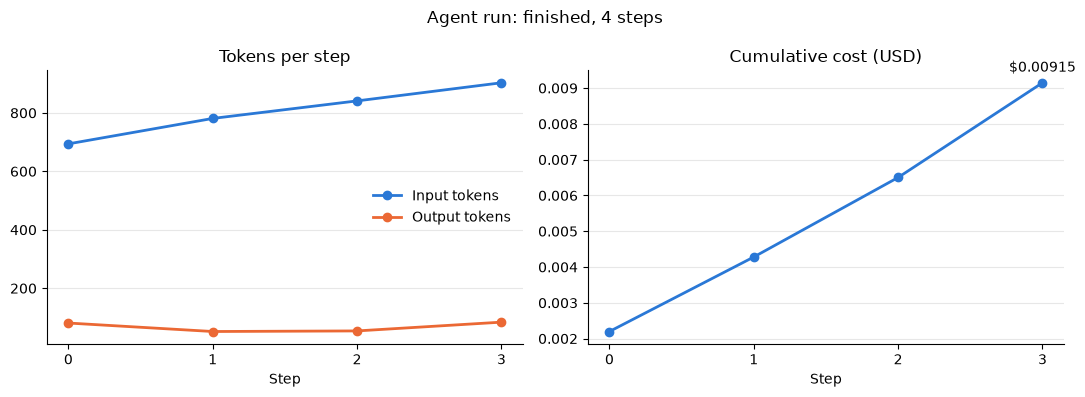

In [10]:
if __name__ == "__main__":
    text = ("I love GenAI. Building agents from scratch is so enlightening. "
            "No longer seems like Science fiction")
    goal = ("How long would it take to read the following text at 200 words per minute? "
            f"The text is between single quotes: '{text}'")

    result = run_agent(goal)
    print_report(goal, result)
    if result["steps"]:  # nothing to graph if the first API call failed
        plot_metrics(result)